### Model training - clustring

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\shali\OneDrive\Desktop\FinanceX\data\clustering_datasets.csv")
df.head()

,customer_id,monthly_income,monthly_expense,savings_rate,avg_transaction_amount,transaction_frequency,food_ratio,shopping_ratio,travel_ratio,entertainment_ratio,other_ratio
0,1,45959.25,42487.96,0.075530,883.63,48.0833,0.384917,0.133842,0.127589,0.080412,0.273240
1,2,27766.85,23649.99,0.148265,817.87,28.9167,0.229642,0.175236,0.103009,0.084579,0.407534
2,3,56283.88,47121.93,0.162781,782.11,60.2500,0.237364,0.386796,0.127781,0.074926,0.173133
3,4,49647.33,40595.15,0.182330,818.73,49.5833,0.412103,0.146825,0.109314,0.075535,0.256223
4,5,40250.89,24048.26,0.402541,775.75,31.0000,0.243864,0.173567,0.105155,0.089637,0.387777


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   monthly_income          50000 non-null  float64
 1   monthly_expense         50000 non-null  float64
 2   savings_rate            50000 non-null  float64
 3   avg_transaction_amount  50000 non-null  float64
 4   transaction_frequency   50000 non-null  float64
 5   food_ratio              50000 non-null  float64
 6   shopping_ratio          50000 non-null  float64
 7   travel_ratio            50000 non-null  float64
 8   entertainment_ratio     50000 non-null  float64
 9   other_ratio             50000 non-null  float64
dtypes: float64(10)
memory usage: 3.8 MB


In [4]:
df.drop(columns=['customer_id'], inplace=True)

In [6]:
x = df

In [7]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

In [8]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
x_pca = pca.fit_transform(x_scaled)

In [9]:
from sklearn.cluster import KMeans
wcss = []

for k in range(1,11):
    model = KMeans(n_clusters=k, init='k-means++', random_state=42)
    model.fit(x_pca)
    wcss.append(model.inertia_)

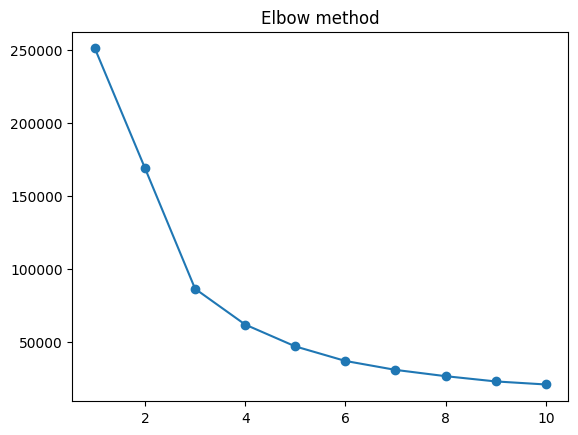

In [10]:
plt.plot(range(1,11),wcss,marker='o')
plt.title('Elbow method')
plt.show()

In [11]:
from kneed import KneeLocator
kl=KneeLocator(range(1,11),wcss,curve="convex",direction="decreasing")
kl.elbow

np.int64(3)

In [12]:
from sklearn.cluster import KMeans
model = KMeans(n_clusters=3,init='k-means++',random_state=42)
clusters = model.fit_predict(x_pca)

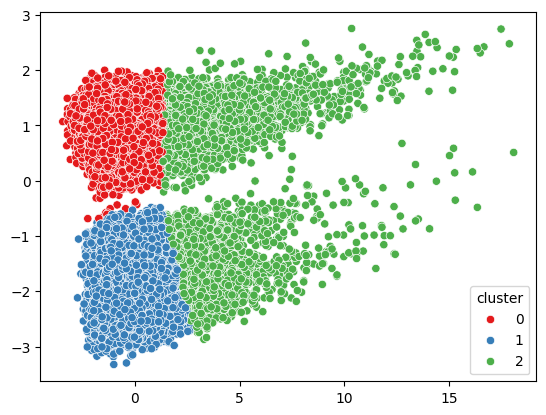

In [15]:
plt.Figure(figsize=(10,6))
sns.scatterplot(x=x_pca[:,0],y=x_pca[:,1],hue=df['cluster'],palette='Set1')
plt.show()

In [16]:
from sklearn.metrics import silhouette_score
print('Silhouette Score:', silhouette_score(x_pca, clusters))

Silhouette Score: 0.5337187869378613


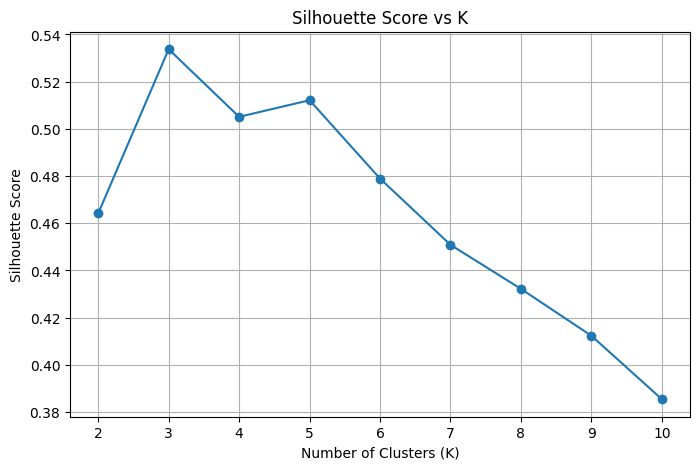

In [17]:
from sklearn.metrics import silhouette_score
silhouette_scores = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        init="k-means++"
    )
    labels = model.fit_predict(x_pca)
    score = silhouette_score(x_pca, labels)
    silhouette_scores.append(score)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs K")
plt.grid()
plt.show()

In [32]:
from sklearn.cluster import KMeans

model = KMeans(
    n_clusters=3,
    init="k-means++",
    random_state=42
)

clusters = model.fit_predict(x_pca)

In [34]:
from sklearn.pipeline import Pipeline

clustering_pipeline = Pipeline([
    ("scaler", scaler),
    ("pca", pca),
    ("kmeans", model)
])

clustering_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('pca', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['monthly_income','monthly_expense','savings_rate',...,'travel_ratio', 'entertainment_ratio','other_ratio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [39]:
print(clustering_pipeline)
print("Final K:", clustering_pipeline.named_steps["kmeans"].n_clusters)

Pipeline(steps=[('scaler', StandardScaler()), ('pca', PCA(n_components=2)),
                ('kmeans', KMeans(n_clusters=3, random_state=42))])
Final K: 3


In [41]:
import joblib

joblib.dump(
    clustering_pipeline,
    r"C:\Users\shali\OneDrive\Desktop\FinanceX\model\FinanceX_clustering_model.pkl"
)

['C:\\Users\\shali\\OneDrive\\Desktop\\FinanceX\\model\\FinanceX_clustering_model.pkl']